# MovieLens Collaborative Filtering

This is a recommendation project.

MovieLens small has user ratings for movies. I will look at the rating distribution and the most rated titles, then train two models on the same 80/20 split of ratings. The first is Truncated SVD on the user-item matrix, a usual collaborative baseline. The second is a neural model with user and movie embeddings. The deep model is the one I want here. I will compare RMSE and save the neural model.


In [2]:
import kagglehub

path = kagglehub.dataset_download("shubhammehta21/movie-lens-small-latest-dataset")
print("Path to dataset files:", path)


Path to dataset files: C:\Users\Administrator\.cache\kagglehub\datasets\shubhammehta21\movie-lens-small-latest-dataset\versions\1


In [3]:
import os
import glob
import pandas as pd

ratings_path = glob.glob(os.path.join(path, "**", "ratings.csv"), recursive=True)[0]
ratings = pd.read_csv(ratings_path)
ratings.head()


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [4]:
print(ratings.shape)
print(ratings["rating"].value_counts().sort_index())


(100836, 4)
rating
0.5     1370
1.0     2811
1.5     1791
2.0     7551
2.5     5550
3.0    20047
3.5    13136
4.0    26818
4.5     8551
5.0    13211
Name: count, dtype: int64


In [5]:
movies_path = glob.glob(os.path.join(path, "**", "movies.csv"), recursive=True)[0]
movies = pd.read_csv(movies_path)
ratings = ratings.merge(movies[["movieId", "title"]], on="movieId")
movies.head()


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


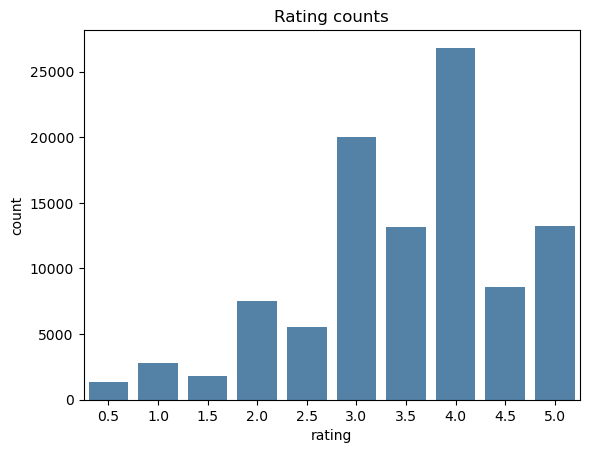

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=ratings, x="rating", color="steelblue")
plt.title("Rating counts")
plt.show()


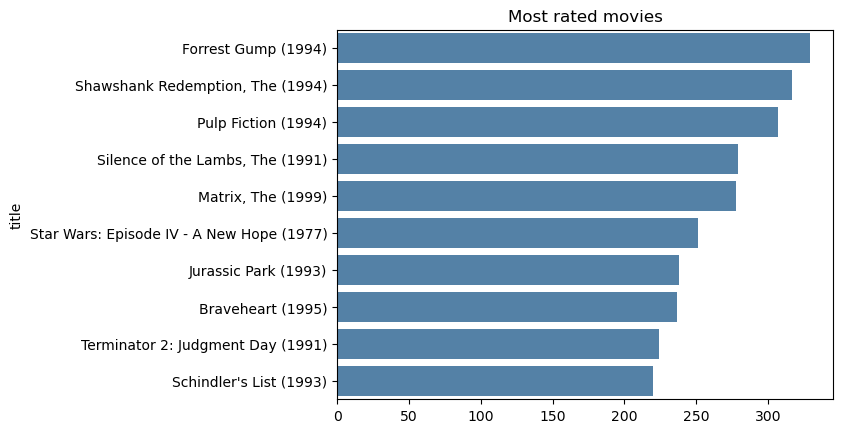

In [7]:
top = ratings["title"].value_counts().head(10)
sns.barplot(x=top.values, y=top.index, color="steelblue")
plt.title("Most rated movies")
plt.show()


In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

ue = LabelEncoder()
ie = LabelEncoder()
ratings["u"] = ue.fit_transform(ratings["userId"])
ratings["i"] = ie.fit_transform(ratings["movieId"])
n_user = ratings["u"].nunique()
n_item = ratings["i"].nunique()

x_train, x_test, y_train, y_test = train_test_split(
    ratings[["u", "i"]], ratings["rating"], test_size=0.20, random_state=42
)
print(n_user, n_item)
print(x_train.shape, x_test.shape)


610 9724
(80668, 2) (20168, 2)


In [9]:
from scipy.sparse import coo_matrix
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import mean_squared_error
import numpy as np

mat = coo_matrix(
    (y_train, (x_train["u"], x_train["i"])),
    shape=(n_user, n_item),
).tocsr()
svd = TruncatedSVD(n_components=32, random_state=42)
user_f = svd.fit_transform(mat)
svd_pred = (user_f[x_test["u"]] * svd.components_.T[x_test["i"]]).sum(axis=1)
print("SVD RMSE", np.sqrt(mean_squared_error(y_test, svd_pred)))


SVD RMSE 3.087659467379582


In [10]:
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

user_in = layers.Input(shape=(1,))
item_in = layers.Input(shape=(1,))
u = layers.Flatten()(layers.Embedding(n_user, 32)(user_in))
it = layers.Flatten()(layers.Embedding(n_item, 32)(item_in))
x = layers.Concatenate()([u, it])
x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.3)(x)
out = layers.Dense(1)(x)
dl = tf.keras.Model([user_in, item_in], out)
dl.compile(optimizer="adam", loss="mse")
hist = dl.fit(
    [x_train["u"], x_train["i"]], y_train,
    validation_split=0.1,
    epochs=8,
    batch_size=256,
    callbacks=[EarlyStopping(patience=2, restore_best_weights=True)],
    verbose=1,
)
dl_pred = dl.predict([x_test["u"], x_test["i"]], verbose=0).ravel()
print("Neural CF RMSE", np.sqrt(mean_squared_error(y_test, dl_pred)))


Epoch 1/8
284/284 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 3.5022 - val_loss: 0.8500
Epoch 2/8
284/284 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9162 - val_loss: 0.8145
Epoch 3/8
284/284 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8626 - val_loss: 0.8108
Epoch 4/8
284/284 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8371 - val_loss: 0.8128
Epoch 5/8
284/284 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8167 - val_loss: 0.8081
Epoch 6/8
284/284 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8072 - val_loss: 0.8078
Epoch 7/8
284/284 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7992 - val_loss: 0.8056
Epoch 8/8
284/284 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7922 - val_loss: 0.8054
Neural CF RMSE 0.902449542036364


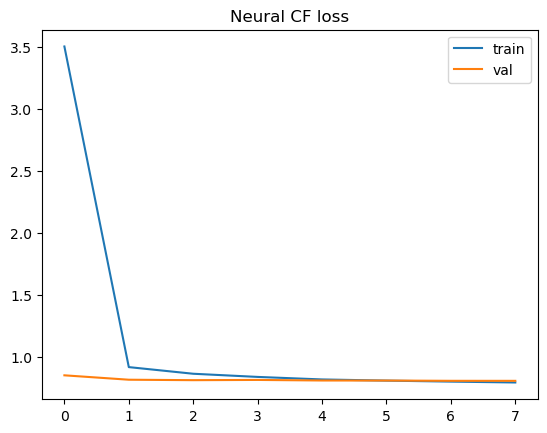

In [11]:
plt.plot(hist.history["loss"], label="train")
plt.plot(hist.history["val_loss"], label="val")
plt.title("Neural CF loss")
plt.legend()
plt.show()


In [12]:
user = int(x_test["u"].iloc[0])
users = np.full((n_item, 1), user)
items = np.arange(n_item).reshape(-1, 1)
scores = dl([users, items], training=False).numpy().ravel()

seen = x_train.loc[x_train["u"] == user, "i"].to_numpy()
scores[seen] = -1

top = ie.inverse_transform(np.argsort(-scores)[:5])
print(movies.loc[movies["movieId"].isin(top), "title"])


1037    Vampire in Venice (Nosferatu a Venezia) (Nosfe...
3505                       Phantom of the Paradise (1974)
5407        Andalusian Dog, An (Chien andalou, Un) (1929)
7114                                       Troll 2 (1990)
7621                                     Submarine (2010)
Name: title, dtype: object


In [13]:
dl.save("movielens_ncf.keras")


# Conclusion

I trained Truncated SVD and a neural collaborative filter on the same 80/20 split of MovieLens ratings. SVD compresses the user-item matrix. The neural model learns a 32-d embedding for each user and each movie, then a small dense head predicts the rating; that is the deep learning model for this task. RMSE is the number to watch. The neural model is saved as movielens_ncf.keras.
